#1. Inspect raw dataset

In [1]:
import pandas as pd
import numpy as np

df_disney = pd.read_csv('disney_plus_titles.csv')
df_streaming = pd.read_csv('platforms.csv')

In [2]:
df_disney.head(2)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Duck the Halls: A Mickey Mouse Christmas Special,"Alonso Ramirez Ramos, Dave Wasson","Chris Diamantopoulos, Tony Anselmo, Tress MacN...",NaN,"November 26, 2021",2016,TV-G,23 min,"Animation, Family",Join Mickey and the gang as they duck the halls!
1,s2,Movie,Ernest Saves Christmas,John Cherry,"Jim Varney, Noelle Parker, Douglas Seale",NaN,"November 26, 2021",1988,PG,91 min,Comedy,Santa Claus passes his magic bag to a new St. ...


In [3]:
# Inspect shapes, columns, and missing values
print("Disney+ Dataset Shape:", df_disney.shape)
print("Disney+ Missing Values:\n", df_disney.isnull().sum())

print("\nStreaming Platforms Shape:", df_streaming.shape)
print("Streaming Platforms Columns:", df_streaming.columns.tolist())
print(df_streaming.head(2))

Disney+ Dataset Shape: (1450, 12)
Disney+ Missing Values:
 show_id           0
type              0
title             0
director        473
cast            190
country         219
date_added        3
release_year      0
rating            3
duration          0
listed_in         0
description       0
dtype: int64

Streaming Platforms Shape: (9515, 11)
Streaming Platforms Columns: ['Unnamed: 0', 'ID', 'Title', 'Year', 'Age', 'Rotten Tomatoes', 'Netflix', 'Hulu', 'Prime Video', 'Disney+', 'Type']
   Unnamed: 0  ID         Title  Year  Age Rotten Tomatoes  Netflix  Hulu  \
0           0   1  The Irishman  2019  18+          98/100        1     0   
1           1   2        Dangal  2016   7+          97/100        1     0   

   Prime Video  Disney+  Type  
0            0        0     0  
1            0        0     0  


#2. Data Cleaning

In [4]:
# 1. Drop unnecessary index columns from df_streaming
df_streaming = df_streaming.drop(columns=['Unnamed: 0', 'ID'], errors='ignore')

# 2. Standardize movie titles into a helper column for exact matching
df_disney['title_clean'] = df_disney['title'].str.lower().str.strip()
df_streaming['title_clean'] = df_streaming['Title'].str.lower().str.strip()

# 3. Filter df_streaming for Disney+ titles only (Disney+ == 1)
df_streaming_disney = df_streaming[df_streaming['Disney+'] == 1].copy()

In [5]:
# 4. Left Join: Enrich Disney+ catalog with Rotten Tomatoes scores & Age brackets
cols_to_merge = ['title_clean', 'Year', 'Age', 'Rotten Tomatoes']
df_merged = pd.merge(df_disney,df_streaming_disney[cols_to_merge].drop_duplicates(subset=['title_clean']), on='title_clean', how='left')

print("Merged Dataset Shape:", df_merged.shape)
print("Titles with Rotten Tomatoes Score:", df_merged['Rotten Tomatoes'].notnull().sum())

Merged Dataset Shape: (1450, 16)
Titles with Rotten Tomatoes Score: 781


#STEP 3: MISSING VALUES & FEATURE ENGINEERING

In [6]:
# 1. Fill missing metadata values
df_merged['director'] = df_merged['director'].fillna('Unknown')
df_merged['cast'] = df_merged['cast'].fillna('Unknown')
df_merged['country'] = df_merged['country'].fillna('United States')
df_merged['rating'] = df_merged['rating'].fillna('Unrated')

In [7]:
# 2. Convert 'date_added' to datetime and extract year/month
df_merged['date_added'] = pd.to_datetime(df_merged['date_added'].str.strip(), errors='coerce')
df_merged['added_year'] = df_merged['date_added'].dt.year
df_merged['added_month'] = df_merged['date_added'].dt.month

In [8]:
# 3. Feature 1: Release Lag (Years between original release and Disney+ launch)
#Subtract the year the movie was made (release_year) from the year it appeared on Disney+ (added_year).

df_merged['release_lag'] = (df_merged['added_year'] - df_merged['release_year']).clip(lower=0)

##clip(lower=0) because "Any number smaller than 0 becomes 0" (no negative ages).

Distinguish between brand-new release or an old catalog title

In [9]:
# 4. Feature 2: Content Origin (Same-Year Original vs. Legacy Catalog)
df_merged['content_origin'] = np.where(df_merged['release_lag'] == 0, 'Same-Year / Original Release', 'Legacy / Catalog Content')

In [10]:
# 5. Feature 3: Numeric Duration (Minutes for Movies, Seasons for TV Shows)
df_merged['duration_num'] = df_merged['duration'].str.extract(r'(\d+)').astype(float)

# 6. Feature 4: Numeric Rotten Tomatoes Score ("98/100" -> 98.0)
df_merged['rt_score'] = df_merged['Rotten Tomatoes'].astype(str).str.extract(r'(\d+)').astype(float)


In [11]:
# 7. Feature 5: Genre Engineering (Primary Genre + Multi-Genre Binary Flags)
df_merged['primary_genre'] = df_merged['listed_in'].str.split(',').str[0].str.strip()
df_merged['is_animation'] = df_merged['listed_in'].str.contains('Animation', case=False).astype(int)
df_merged['is_family'] = df_merged['listed_in'].str.contains('Family', case=False).astype(int)
df_merged['is_documentary'] = df_merged['listed_in'].str.contains('Documentary', case=False).astype(int)
df_merged['genre_count'] = df_merged['listed_in'].apply(lambda x: len(x.split(',')))

# Drop helper column and inspect final clean dataset
df_clean = df_merged.drop(columns=['title_clean'])
print("\nPreview of Engineered Features:")
print(df_clean[['title', 'type', 'release_lag', 'content_origin', 'duration_num', 'rt_score', 'primary_genre', 'is_animation', 'genre_count']].head(10))

# Export cleaned data
df_clean.to_csv('disney_plus_cleaned.csv', index=False)


Preview of Engineered Features:
                                              title     type  release_lag  \
0  Duck the Halls: A Mickey Mouse Christmas Special    Movie          5.0   
1                            Ernest Saves Christmas    Movie         33.0   
2                      Ice Age: A Mammoth Christmas    Movie         10.0   
3                        The Queen Family Singalong    Movie          0.0   
4                             The Beatles: Get Back  TV Show          0.0   
5                                 Becoming Cousteau    Movie          0.0   
6                                           Hawkeye  TV Show          0.0   
7                            Port Protection Alaska  TV Show          6.0   
8                         Secrets of the Zoo: Tampa  TV Show          2.0   
9             A Muppets Christmas: Letters To Santa    Movie         13.0   

                 content_origin  duration_num  rt_score     primary_genre  \
0      Legacy / Catalog Content          2

#EDA Process

In [12]:
df_clean.groupby('content_origin')['rt_score'].agg(['count', 'mean', 'median'])

,count,mean,median
content_origin,,,
Legacy / Catalog Content,683,58.338214,58.0
Same-Year / Original Release,98,53.377551,50.5


Over-indexing homepage Hero Banner exclusively on brand-new, same-year releases introduces a high risk of user dissatisfaction and early session bounce. To optimize content discovery and retention, Disney+ should rebalance its homepage merchandising toward a hybrid spotlight strategy (e.g., pairing new Originals with high-performing legacy catalog titles in "Up Next" bundles and top-row carousels) while surfacing under-exposed catalog gems.

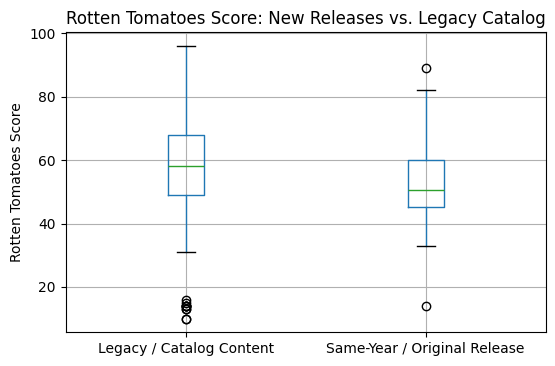

,mean,median,count
is_documentary,,,
0,60.640986,60.0,649
1,43.333333,43.0,132


In [13]:
import matplotlib.pyplot as plt

# Filter out rows where rt_score is missing (NaN) so matplotlib doesn't complain
df_rated = df_clean.dropna(subset=['rt_score'])

#Boxplot comparing rt_score by content_origin
df_rated.boxplot(column='rt_score', by='content_origin', figsize=(6, 4))
plt.title('Rotten Tomatoes Score: New Releases vs. Legacy Catalog')
plt.suptitle('')  # Removes the default messy pandas subtitle
plt.ylabel('Rotten Tomatoes Score')
plt.xlabel('')
plt.show()


df_clean.groupby('is_animation')['rt_score'].agg(['mean', 'median', 'count'])
df_clean.groupby('is_documentary')['rt_score'].agg(['mean', 'median', 'count'])

In [14]:
genre_summary = df_clean.groupby('primary_genre')['rt_score'].agg(['count', 'mean', 'median'])

# Filter for genres with at least 10 rated titles, then grab top 5
genre_summary[genre_summary['count'] >= 10].sort_values(by='mean', ascending=False).head(5)

,count,mean,median
primary_genre,,,
Action-Adventure,225,64.333333,65.0
Biographical,28,63.107143,62.0
Comedy,108,59.592593,59.0
Coming of Age,41,58.731707,58.0
Animation,193,57.953368,55.0


#Movie Runtime vs. Rotten Tomatoes Score

Correlation between Movie Duration and RT Score: 0.478


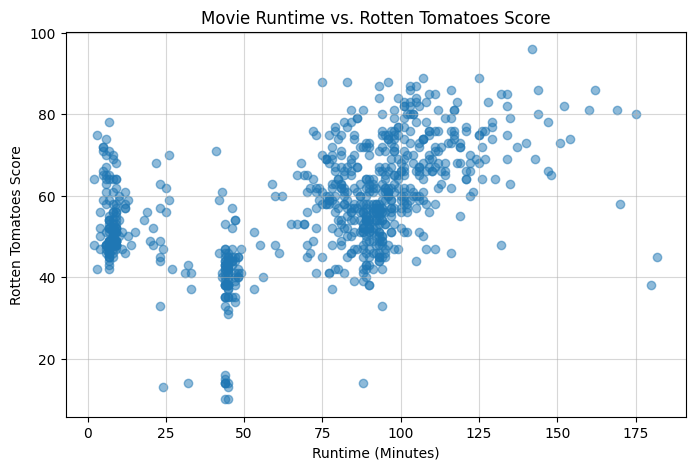

In [15]:
#Filter for Movies only (where rt_score is not missing)
df_movies = df_clean[(df_clean['type'] == 'Movie') & (df_clean['rt_score'].notnull())]

#Check the correlation number between 'duration_num' and 'rt_score'
correlation = df_movies['duration_num'].corr(df_movies['rt_score'])
print(f"Correlation between Movie Duration and RT Score: {correlation:.3f}")

# Scatter Plot using plt.scatter(x, y, alpha=0.5)
plt.figure(figsize=(8, 5))

plt.scatter(df_movies['duration_num'], df_movies['rt_score'], alpha=0.5, color='#1f77b4')

plt.title('Movie Runtime vs. Rotten Tomatoes Score')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('Rotten Tomatoes Score')
plt.grid(True, linestyle='-', alpha=0.5)
plt.show()

**Correlation = 0.478 -> full-length feature films score markedly higher than short-form films/specials on Disney+.**

#Seasonality & Release Cadence (When does Disney+ drop content?)

In [16]:
# 1. Multivariate Correlation Matrix across key numeric features (Movies)
num_cols = ['rt_score', 'duration_num', 'release_lag', 'is_animation', 'is_documentary', 'genre_count']
corr_matrix = df_movies[num_cols].corr()
print("Correlation Matrix (Movies):")
print(corr_matrix.round(2))

# 2. 3-Way Interaction: Content Origin x Is Animation -> RT Score
print("\nRT Score by Content Origin AND Animation:")
print(df_rated.groupby(['content_origin', 'is_animation'])['rt_score'].agg(['count', 'mean', 'median']))

Correlation Matrix (Movies):
                rt_score  duration_num  release_lag  is_animation  \
rt_score            1.00          0.48        -0.08          0.19   
duration_num        0.48          1.00        -0.29         -0.50   
release_lag        -0.08         -0.29         1.00          0.29   
is_animation        0.19         -0.50         0.29          1.00   
is_documentary     -0.48         -0.14        -0.24         -0.34   
genre_count         0.29          0.05         0.22          0.31   

                is_documentary  genre_count  
rt_score                 -0.48         0.29  
duration_num             -0.14         0.05  
release_lag              -0.24         0.22  
is_animation             -0.34         0.31  
is_documentary            1.00        -0.40  
genre_count              -0.40         1.00  

RT Score by Content Origin AND Animation:
                                           count       mean  median
content_origin               is_animation             

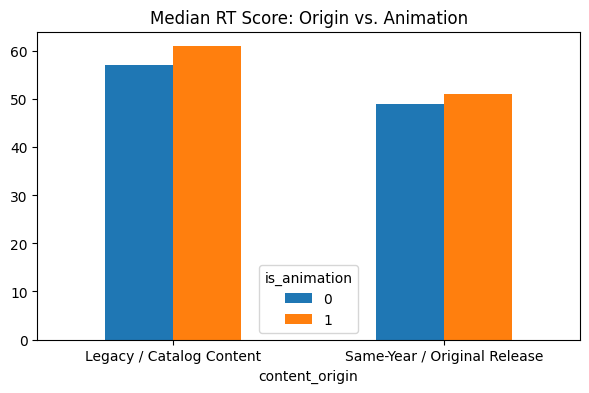

In [17]:
df_rated.groupby(['content_origin', 'is_animation'])['rt_score'].median().unstack().plot(kind='bar', figsize=(7, 4));
plt.title('Median RT Score: Origin vs. Animation');
plt.xticks(rotation=0);
plt.show()



> 1. is_animation has a -0.50 negative correlation with duration_num (because Disney's catalog includes tons of 7–30 minute animated shorts), and duration_num has a +0.48 correlation with rt_score.

-> Even though animated titles are shorter on average (which normally pulls scores down), is_animation still beats non-animation (61.82 vs. 56.28 in Legacy; 55.79 vs. 52.15 in Same-Year Originals)
-> full-length Animated Features are Disney+'s true powerhouse.





> genre_count (+0.29 with rt_score): Titles blending 2–3 genres consistently score higher than single-genre titles.

> is_documentary (-0.48 with rt_score): Documentaries pull down average scores across both buckets (Same-Year Non-Animation drops to a 49.0 median, heavily dragged down by single-genre documentaries).





#5: Predictive Modeling & Content Recommendation System

#Random Forest Classifier (Predicting Crowd-Pleasers)

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

#modeling dataset (Movies with known rt_score)
df_model = df_movies.dropna(subset=['duration_num', 'release_lag', 'rt_score']).copy()

#Target: 1 if Rotten Tomatoes >= 60 ("Fresh"), else 0
df_model['is_fresh'] = (df_model['rt_score'] >= 60).astype(int)

features = ['duration_num', 'release_lag', 'is_animation', 'is_family', 'is_documentary', 'genre_count']
X = df_model[features]
y = df_model['is_fresh']

#80% Train / 20% Test (random_state=42 ensures reproducible results)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print("Classification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 87.26%

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.93      0.89        83
           1       0.91      0.81      0.86        74

    accuracy                           0.87       157
   macro avg       0.88      0.87      0.87       157
weighted avg       0.88      0.87      0.87       157



In [19]:
# Show which features drive "Fresh" ratings the most
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)
print("Feature Importance:\n", importance.round(3))

Feature Importance:
 duration_num      0.522
release_lag       0.190
is_documentary    0.101
is_animation      0.097
genre_count       0.066
is_family         0.024
dtype: float64




> duration_num (52.2%) and release_lag (19%) account for over 71% of what predicts whether a Disney+ movie hits the "Fresh" ($\ge 60$) quality tier.   is_documentary (10.1%) and is_animation (9.7%) act as the key genre signals right behind runtime and catalog age



In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

models = {
    "Logistic Regression (Baseline)": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": f"{accuracy_score(y_test, preds):.2%}",
        "F1-Score": round(f1_score(y_test, preds), 3),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 3)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

                         Model Accuracy  F1-Score  ROC-AUC
Logistic Regression (Baseline)   82.17%     0.791    0.892
                 Decision Tree   81.53%     0.788    0.852
                 Random Forest   87.26%     0.857    0.923


=> Benchmarking three classifiers on the same 80/20 split confirms that Random Forest (100 trees) outperforms both linear and single-tree baselines across every metric, achieving 87.26% accuracy, a 0.857 F1-score, and a 0.923 ROC-AUC (compared to 82.17% accuracy and 0.892 ROC-AUC for Logistic Regression).

In [21]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Score ALL Disney+ Movies (both rated and unrated) using trained Random Forest
all_movies = df_clean[df_clean['type'] == 'Movie'].dropna(subset=['duration_num', 'release_lag']).copy().reset_index(drop=True)
all_movies['fresh_prob'] = rf_model.predict_proba(all_movies[features])[:, 1]

all_movies['score_source'] = np.where(all_movies['rt_score'].notnull(), 'Actual RT Score', 'ML Predicted')

# Unified quality score: use actual rt_score/100 if available, otherwise use the model's predicted fresh_prob
all_movies['quality_score'] = np.where(all_movies['rt_score'].notnull(),all_movies['rt_score'] / 100.0, all_movies['fresh_prob'])

# Content Similarity Matrix using Genres + Plot Description
all_movies['content_soup'] = (all_movies['listed_in'].fillna('') + " " +all_movies['director'].fillna('') + " " +all_movies['cast'].fillna('') + " " +all_movies['description'].fillna(''))
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(all_movies['content_soup'])
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# 3. Recommendation function: blend thematic similarity (60%) + quality protection (40%)
def recommend_up_next(movie_title, top_n=5):
    matches = all_movies[all_movies['title'].str.lower() == movie_title.lower()]
    if matches.empty:
        return f"'{movie_title}' not found in Movie catalog."

    idx = matches.index[0]
    sim_scores = list(enumerate(cosine_sim[idx]))

    # Exclude the movie itself, take top 20 thematically closest titles
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:21]
    movie_indices = [i[0] for i in sim_scores]

    candidates = all_movies.iloc[movie_indices].copy()
    candidates['similarity'] = [i[1] for i in sim_scores]
    candidates['up_next_rank'] = 0.6 * candidates['similarity'] + 0.4 * candidates['quality_score']

    return candidates.sort_values(by='up_next_rank', ascending=False)[
        ['title', 'content_origin', 'primary_genre', 'rt_score', 'fresh_prob', 'up_next_rank']].head(top_n)

In [22]:
print("'Up Next' Carousel sau khi xem 'Jungle Cruise':")
print(recommend_up_next('Jungle Cruise').to_string(index=False))

'Up Next' Carousel sau khi xem 'Jungle Cruise':
                  title           content_origin    primary_genre  rt_score  fresh_prob  up_next_rank
Marvel Studios' Ant-Man Legacy / Catalog Content Action-Adventure       NaN    0.909904      0.398382
                  Moana Legacy / Catalog Content Action-Adventure      83.0    0.942503      0.380620
       Disney's The Kid Legacy / Catalog Content           Comedy       NaN    0.762622      0.357445
   Mary Poppins Returns Legacy / Catalog Content           Family      73.0    0.925778      0.355871
       Saving Mr. Banks Legacy / Catalog Content     Biographical      77.0    0.914238      0.348788


In [23]:
all_movies['score_source'] = np.where(all_movies['rt_score'].notnull(), 'Actual RT Score', 'ML Predicted')
all_movies.to_csv('disney_tableau_movies.csv', index=False)
df_clean.to_csv('disney_full.csv', index=False)
print("\nCSV published!")


CSV published!
